# **Student Performance prediction**

**Author** : Noorish Fizza

---

**Contact**: Linkedin(www.linkedin.com/in/noorish-fizza-67165938b)


---
**Date**: 22 September , 2026

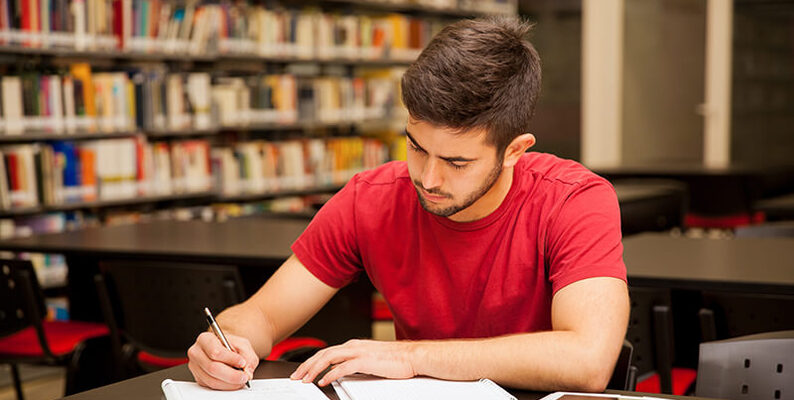

**📊 Dataset: Student Performance (Updated)**

🔑 Columns & Descriptions

1. `StudentID` (float) – Unique identifier for each student.
2. `Name` (string) – Student’s name.
3. `Gender` (Male/Female) – Student’s gender.
4. `AttendanceRate` (float, %) – Percentage of attended classes (70–95%).
5. `StudyHoursPerWeek` (float) – Average hours spent studying per week (8–30 hours).
6. `PreviousGrade` (float) – Grade score from the previous academic term (60–90).
7. `ExtracurricularActivities` (int) – Number of extracurricular activities student participates in (0–3).
8. `ParentalSupport` (High/Medium/Low) – Level of parental academic support.
9. `FinalGrade` (float) – Student’s final grade in the course (62–92).
10. `Study Hours` (float) – Another study-related measure (scale seems different; values from -5 to 5).
11. `Attendance` (%) (float) – Another attendance-related measure (values 50–200, possibly noisy or scaled).
12. `Online Classes Taken` (True/False) – Whether the student took online classes.


## **1.  Data Cleaning**

#### **1.1  Importing Liabraries**

In [75]:
import numpy as np
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt 
from sklearn.ensemble import RandomForestClassifier
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error


#### **1.2 Loading dataset**

In [76]:
df = pd.read_csv(r"C:\Users\fizan\Downloads\student_performance_updated_1000.csv")
df.head(5)

,StudentID,Name,Gender,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,ParentalSupport,FinalGrade,Study Hours,Attendance (%),Online Classes Taken
0,1.0,John,Male,85.0,15.0,78.0,1.0,High,80.0,4.8,59.0,False
1,2.0,Sarah,Female,90.0,20.0,85.0,2.0,Medium,87.0,2.2,70.0,True
2,3.0,Alex,Male,78.0,10.0,65.0,0.0,Low,68.0,4.6,92.0,False
3,4.0,Michael,Male,92.0,25.0,90.0,3.0,High,92.0,2.9,96.0,False
4,5.0,Emma,Female,NaN,18.0,82.0,2.0,Medium,85.0,4.1,97.0,True


#### **1.3 checking datset info**

In [77]:
df.describe()

,StudentID,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,FinalGrade,Study Hours,Attendance (%)
count,960.000000,960.000000,950.000000,967.000000,957.000000,960.000000,976.000000,959.000000
mean,5416.019792,85.510417,17.630526,77.598759,1.520376,80.030208,2.406967,77.248175
std,2653.748319,7.332125,6.272132,10.006640,1.046439,9.493652,1.620267,19.298148
min,1.000000,70.000000,8.000000,60.000000,0.000000,62.000000,-5.000000,50.000000
25%,3113.500000,82.000000,12.000000,70.000000,1.000000,72.000000,1.200000,63.000000
50%,5396.500000,88.000000,18.000000,78.000000,1.000000,80.000000,2.500000,76.000000
75%,7754.750000,91.000000,22.000000,86.000000,2.000000,88.000000,3.700000,89.000000
max,9998.000000,95.000000,30.000000,90.000000,3.000000,92.000000,5.000000,200.000000


In [78]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   StudentID                  960 non-null    float64
 1   Name                       966 non-null    str    
 2   Gender                     952 non-null    str    
 3   AttendanceRate             960 non-null    float64
 4   StudyHoursPerWeek          950 non-null    float64
 5   PreviousGrade              967 non-null    float64
 6   ExtracurricularActivities  957 non-null    float64
 7   ParentalSupport            978 non-null    str    
 8   FinalGrade                 960 non-null    float64
 9   Study Hours                976 non-null    float64
 10  Attendance (%)             959 non-null    float64
 11  Online Classes Taken       975 non-null    object 
dtypes: float64(8), object(1), str(3)
memory usage: 115.5+ KB


#### **1.4 Handling Null Values**

#### **1.4.1 Handling missing values of StudentID column**

In [79]:
df['StudentID'].isnull().value_counts()   # checking how many null values are there
# Reassign StudentID sequentially from 1 to the last row
df['StudentID'] = np.arange(1, len(df) + 1)

df['StudentID'].head()

0    1
1    2
2    3
3    4
4    5
Name: StudentID, dtype: int64

#### **1.4.2 Handling missing values of Name column**

In [80]:
df['Name'].isnull().value_counts()
df.dropna(subset=['Name'],inplace=True)

In [81]:
df.describe()

,StudentID,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,FinalGrade,Study Hours,Attendance (%)
count,966.000000,928.000000,919.000000,934.000000,925.000000,927.000000,943.000000,926.000000
mean,498.961698,85.462284,17.647443,77.602784,1.522162,80.039914,2.400742,77.207343
std,290.199613,7.338383,6.266744,10.014439,1.045913,9.504888,1.620991,19.493871
min,1.000000,70.000000,8.000000,60.000000,0.000000,62.000000,-5.000000,50.000000
25%,246.250000,82.000000,12.000000,70.000000,1.000000,72.000000,1.200000,63.000000
50%,500.500000,88.000000,18.000000,78.000000,1.000000,80.000000,2.500000,76.000000
75%,751.750000,91.000000,22.000000,86.000000,2.000000,88.000000,3.700000,90.000000
max,1000.000000,95.000000,30.000000,90.000000,3.000000,92.000000,5.000000,200.000000


In [82]:
df.columns

Index(['StudentID', 'Name', 'Gender', 'AttendanceRate', 'StudyHoursPerWeek',
       'PreviousGrade', 'ExtracurricularActivities', 'ParentalSupport',
       'FinalGrade', 'Study Hours', 'Attendance (%)', 'Online Classes Taken'],
      dtype='str')

#### **1.4.3 Handling missing values of all numeric column**

In [83]:
# using iterative imputer to fill numerical missing values

df_numeric = df[['AttendanceRate', 'StudyHoursPerWeek',
       'PreviousGrade', 'ExtracurricularActivities','FinalGrade', 'Study Hours', 'Attendance (%)']]
imputer = IterativeImputer(estimator=RandomForestRegressor(random_state=0), max_iter=10, random_state=0)

# Fit and transform the data
df[['AttendanceRate', 'StudyHoursPerWeek','PreviousGrade', 'ExtracurricularActivities','FinalGrade', 'Study Hours', 'Attendance (%)']]= imputer.fit_transform(df_numeric)

c:\Users\fizan\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


In [84]:
df.info()

<class 'pandas.DataFrame'>
Index: 966 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   StudentID                  966 non-null    int64  
 1   Name                       966 non-null    str    
 2   Gender                     919 non-null    str    
 3   AttendanceRate             966 non-null    float64
 4   StudyHoursPerWeek          966 non-null    float64
 5   PreviousGrade              966 non-null    float64
 6   ExtracurricularActivities  966 non-null    float64
 7   ParentalSupport            945 non-null    str    
 8   FinalGrade                 966 non-null    float64
 9   Study Hours                966 non-null    float64
 10  Attendance (%)             966 non-null    float64
 11  Online Classes Taken       942 non-null    object 
dtypes: float64(7), int64(1), object(1), str(3)
memory usage: 119.5+ KB


#### **1.4.4 Handling missing values of Gender column**

In [85]:
df['Gender'].value_counts()


# 1. Define the exact features used to predict Gender
feature_cols = [
    'AttendanceRate', 'StudyHoursPerWeek', 'PreviousGrade', 
    'ExtracurricularActivities', 'FinalGrade', 'Study Hours', 'Attendance (%)'
]

# 2. Split your original dataframe based on missing Gender values
df_missing = df[df['Gender'].isnull()].copy()
df_clean = df[df['Gender'].notnull()].copy()

# 3. Check for edge case: Ensure you actually have missing values to predict
if not df_missing.empty and not df_clean.empty:
    
    # 4. Define training features and targets
    X_train = df_clean[feature_cols]
    y_train = df_clean['Gender']
    X_missing = df_missing[feature_cols]
    
    # 5. Train the model
    clf = RandomForestClassifier(random_state=42)
    clf.fit(X_train, y_train)
    
    # 6. Generate the missing Gender values
    predicted_categories = clf.predict(X_missing)
    
    # 7. CRITICAL STEP: This permanently modifies your original 'df' 
    df.loc[df_missing.index, 'Gender'] = predicted_categories


df.info()


<class 'pandas.DataFrame'>
Index: 966 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   StudentID                  966 non-null    int64  
 1   Name                       966 non-null    str    
 2   Gender                     966 non-null    str    
 3   AttendanceRate             966 non-null    float64
 4   StudyHoursPerWeek          966 non-null    float64
 5   PreviousGrade              966 non-null    float64
 6   ExtracurricularActivities  966 non-null    float64
 7   ParentalSupport            945 non-null    str    
 8   FinalGrade                 966 non-null    float64
 9   Study Hours                966 non-null    float64
 10  Attendance (%)             966 non-null    float64
 11  Online Classes Taken       942 non-null    object 
dtypes: float64(7), int64(1), object(1), str(3)
memory usage: 151.8+ KB


In [86]:
df['Online Classes Taken'] = df['Online Classes Taken'].astype('str')


#### **1.4.5 Handling missing values of ParentalSupport column**

In [87]:


# 1. Define the base numeric features that never have missing values
# 1. Define the exact features used to predict Gender
feature_cols = [
    'AttendanceRate', 'StudyHoursPerWeek', 'PreviousGrade', 
    'ExtracurricularActivities', 'FinalGrade', 'Study Hours', 'Attendance (%)'
]

# 2. Split your original dataframe based on missing Gender values
df_missing = df[df['ParentalSupport'].isnull()].copy()
df_clean = df[df['ParentalSupport'].notnull()].copy()

# 3. Check for edge case: Ensure you actually have missing values to predict
if not df_missing.empty and not df_clean.empty:
    
    # 4. Define training features and targets
    X_train = df_clean[feature_cols]
    y_train = df_clean['ParentalSupport']
    X_missing = df_missing[feature_cols]
    
    # 5. Train the model
    clf = RandomForestClassifier(random_state=42)
    clf.fit(X_train, y_train)
    
    # 6. Generate the missing Gender values
    predicted_categories = clf.predict(X_missing)
    
    # 7. CRITICAL STEP: This permanently modifies your original 'df' 
    df.loc[df_missing.index, 'ParentalSupport'] = predicted_categories


#### **1.4.6 Handling missing values of Online Classes Taken column**

In [88]:
feature_cols = [
    'AttendanceRate', 'StudyHoursPerWeek', 'PreviousGrade', 
    'ExtracurricularActivities', 'FinalGrade', 'Study Hours', 'Attendance (%)'
]

# 2. Split your original dataframe based on missing Gender values
df_missing = df[df['Online Classes Taken'].isnull()].copy()
df_clean = df[df['Online Classes Taken'].notnull()].copy()

# 3. Check for edge case: Ensure you actually have missing values to predict
if not df_missing.empty and not df_clean.empty:
    
    # 4. Define training features and targets
    X_train = df_clean[feature_cols]
    y_train = df_clean['Online Classes Taken']
    X_missing = df_missing[feature_cols]
    
    # 5. Train the model
    clf = RandomForestClassifier(random_state=42)
    clf.fit(X_train, y_train)
    
    # 6. Generate the missing Gender values
    predicted_categories = clf.predict(X_missing)
    
    # 7. CRITICAL STEP: This permanently modifies your original 'df' 
    df.loc[df_missing.index, 'Online Classes Taken'] = predicted_categories

In [89]:
df.info() # All null values are removed

<class 'pandas.DataFrame'>
Index: 966 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   StudentID                  966 non-null    int64  
 1   Name                       966 non-null    str    
 2   Gender                     966 non-null    str    
 3   AttendanceRate             966 non-null    float64
 4   StudyHoursPerWeek          966 non-null    float64
 5   PreviousGrade              966 non-null    float64
 6   ExtracurricularActivities  966 non-null    float64
 7   ParentalSupport            966 non-null    str    
 8   FinalGrade                 966 non-null    float64
 9   Study Hours                966 non-null    float64
 10  Attendance (%)             966 non-null    float64
 11  Online Classes Taken       966 non-null    str    
dtypes: float64(7), int64(1), str(4)
memory usage: 156.1 KB


## **1.5 Exploratory Data Analysis**

In [90]:
import plotly.express as px

fig = px.box(
    df,
    x="Gender",
    y="AttendanceRate",
    color="Gender",
    points="all",
    title="Attendance Rate by Gender",
    labels={"Gender": "Gender", "AttendanceRate": "Attendance Rate (%)"}
)

fig.show()

In [91]:
fig = px.box(
    df,
    x="Gender",
    y="PreviousGrade",
    color="Gender",
    points="all",
    title="Previous Grade by Gender",
    labels={
        "Gender": "Gender",
        "PreviousGrade": "Previous Grade"
    }
)

fig.show()

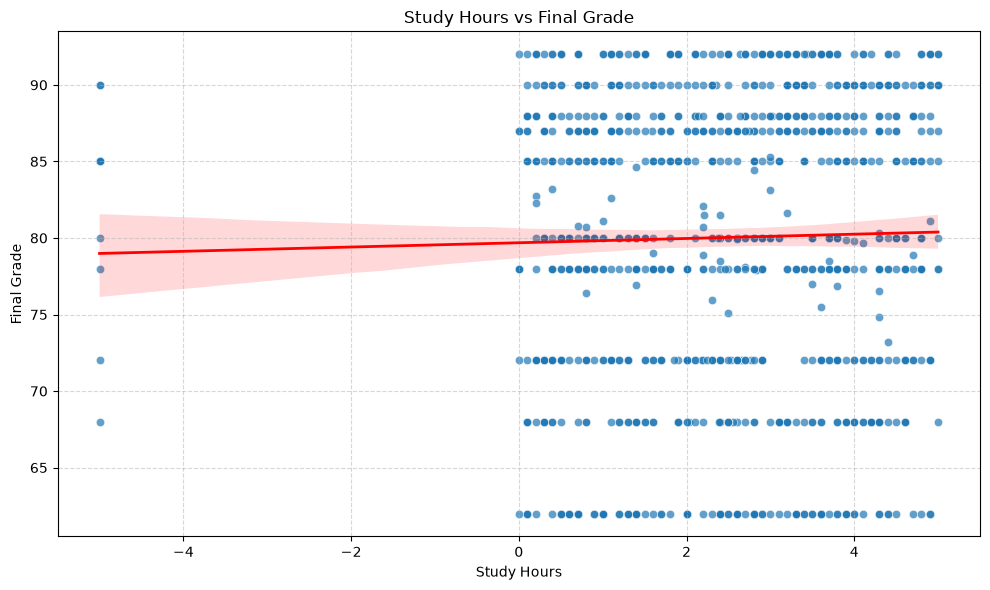

In [92]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='Study Hours', y='FinalGrade', alpha=0.7)
sns.regplot(data=df, x='Study Hours', y='FinalGrade', scatter=False, color='red',
            line_kws={'linewidth': 2})
plt.title('Study Hours vs Final Grade')
plt.xlabel('Study Hours')
plt.ylabel('Final Grade')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## **observation**
1. median of male attendence rate is 85 while female attendence rate is 88 which shows minimal increment of attendence rate based on gender.
2. median of male previos score is 78 while female previous score is 82 which shows minimal increment of previos grade score based on gender.




## **1.6 Encode the data**

In [93]:
df.drop(columns=['Name'], inplace=True)

In [94]:
df.info()

<class 'pandas.DataFrame'>
Index: 966 entries, 0 to 999
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   StudentID                  966 non-null    int64  
 1   Gender                     966 non-null    str    
 2   AttendanceRate             966 non-null    float64
 3   StudyHoursPerWeek          966 non-null    float64
 4   PreviousGrade              966 non-null    float64
 5   ExtracurricularActivities  966 non-null    float64
 6   ParentalSupport            966 non-null    str    
 7   FinalGrade                 966 non-null    float64
 8   Study Hours                966 non-null    float64
 9   Attendance (%)             966 non-null    float64
 10  Online Classes Taken       966 non-null    str    
dtypes: float64(7), int64(1), str(3)
memory usage: 135.9 KB


In [95]:
df['Online Classes Taken'].value_counts()

Online Classes Taken
True     492
False    474
Name: count, dtype: int64

In [96]:
# using label encoder to encode the data

l1 = LabelEncoder()
l2 = LabelEncoder()
l3 = LabelEncoder()

df['Gender'] = l1.fit_transform(df[['Gender']])
df['ParentalSupport'] = l2.fit_transform(df[['ParentalSupport']])
df['Online Classes Taken'] = l3.fit_transform(df[['Online Classes Taken']])


c:\Users\fizan\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_label.py:120: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\fizan\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_label.py:120: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\fizan\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_label.py:120: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [97]:
df.head()

,StudentID,Gender,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,ParentalSupport,FinalGrade,Study Hours,Attendance (%),Online Classes Taken
0,1,1,85.00,15.0,78.0,1.0,0,80.0,4.8,59.0,0
1,2,0,90.00,20.0,85.0,2.0,2,87.0,2.2,70.0,1
2,3,1,78.00,10.0,65.0,0.0,1,68.0,4.6,92.0,0
3,4,1,92.00,25.0,90.0,3.0,0,92.0,2.9,96.0,0
4,5,0,87.74,18.0,82.0,2.0,2,85.0,4.1,97.0,1


## **1.7 Training the model**

In [98]:
# splitting data into train and test
x = df.drop(columns=['FinalGrade'])
y = df['FinalGrade']

x_train ,  x_test , y_train  , y_test = train_test_split(x,y,random_state=42 , test_size=0.2)


In [99]:
# linear regression model
# model = LinearRegression()
# model.fit(x_train,y_train)
# y_pred = model.predict(x_test)
# mean_squared_error(y_test,y_pred )
# mean_absolute_error(y_test,y_pred)
# print(model.score(x_test,y_test))

In [100]:
# model1 = KNeighborsRegressor()
# model1.fit(x_train,y_train)
# y_pred1 = model1.predict(x_test)
# print(mean_squared_error(y_test,y_pred1 ))
# print(mean_absolute_error(y_test,y_pred1))
# print(model1.score(x_test,y_test))

In [101]:
# model2 = KNeighborsRegressor()
# model2.fit(x_train,y_train)
# y_pred2 = model2.predict(x_test)
# print(mean_squared_error(y_test,y_pred2 ))
# print(mean_absolute_error(y_test,y_pred2))
# print(model2.score(x_test,y_test))

In [102]:
# model3 = SVR()
# model3.fit(x_train,y_train)
# prd = model3.predict(x_test)
# print(mean_absolute_error(y_test,prd))

In [104]:

# GaussianNB is for classification; FinalGrade is continuous, so use a regressor
model = DecisionTreeRegressor(random_state=42)
model.fit(x_train, y_train)
y_pred = model.predict(x_test)

print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("R²:", model.score(x_test, y_test))

MAE: 10.617268041237113
MSE: 165.26472835051547
R²: -0.7522277360437288
